# Taller: investigar con bases de datos existentes
## Tabaco (activo y pasivo) y riesgo de muerte — Encuesta Nacional de Salud 2016-17

**Versión FACILITADOR (con soluciones)**

**Pregunta de investigación**
1. ¿Cuál es la prevalencia de fumadores y de fumadores pasivos en Chile?
2. ¿Cuál es la asociación entre la exposición al tabaco y el riesgo de muerte?

**Qué vamos a hacer:** ir de la pregunta al resultado con datos reales:
`pregunta → datos → prevalencias → asociación con la muerte → ¿podemos creer el resultado?`.

**Sobre el uso de los datos.** Las bases de la ENS son públicas, anonimizadas y de descarga libre en
[epi.minsal.cl/bases-de-datos](https://epi.minsal.cl/bases-de-datos/). Las condiciones de uso del Minsal piden
**usarlas solo para investigación, citar la fuente y enviar copia de las publicaciones al Minsal**
([condiciones](https://epi.minsal.cl/condiciones-de-uso/)).

## 0. Preparar el entorno

In [ ]:
# Solo hace falta en Google Colab o si faltan librerías (puedes ignorar si ya las tienes)
%pip install -q pandas numpy scipy pyreadstat lifelines matplotlib

In [2]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, pyreadstat
from scipy import stats
from lifelines import CoxPHFitter, KaplanMeierFitter
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

# Ruta al archivo. Cámbiala si lo guardaste en otro lugar.
RUTA = Path("datos/Base de datos Encuesta Nacional de Salud 2016-2017(ENS)+DEF2023.sav")
RUTA.exists()

True

## 1. Conocer la base (ejemplo resuelto)

La base **ENS 2016-17 + defunciones 2023** une la encuesta con los registros de muerte hasta 2023.
**Cada fila es una persona.** Antes de analizar, hay que entender una idea: el **peso**.

### ¿Qué es el peso y para qué lo necesitamos?

La encuesta no preguntó a todos los chilenos: entrevistó a 6.233 personas elegidas por sorteo.
Lo que queremos decir al final es algo sobre **Chile**, no sobre esas 6.233 personas. Pero el sorteo no dio a todos la misma
probabilidad de salir, y algunos grupos quedaron sobrerrepresentados (verás un caso en el ejercicio 1).

Para corregirlo, cada persona trae un **peso**: **a cuántas personas de Chile representa**.
Si alguien tiene peso 2.000, sus respuestas valen por 2.000 personas. Al calcular un porcentaje, cada persona cuenta según su peso:
eso es una **prevalencia ponderada**. Sin pesos, calcularíamos el porcentaje de la *muestra* y no el de *Chile*.

El sorteo fue además **por etapas** (se eligieron zonas geográficas llamadas *conglomerados*, dentro de grupos llamados *estratos*).
Las personas de un mismo conglomerado se parecen entre sí, así que hay **menos información** que la que sugiere el número de encuestados.
Por eso el intervalo de confianza debe calcularse usando ese diseño. Las funciones del taller ya lo hacen; tú solo debes saber que existe.

El [manual de uso](https://epi.minsal.cl/wp-content/uploads/2019/02/Manual_de_Uso_de_la_base_de_datos_de_la_Encuesta_Nacional_de_Salud_2016_F1_F2_F4_EX1_EX2_14022019.pdf)
indica que, para las preguntas del **cuestionario F1** (donde está el tabaco), el peso es la columna `Fexp_F1p_Corr`.

In [3]:
df, meta = pyreadstat.read_sav(RUTA)
etiq_var = meta.column_names_to_labels      # nombre -> descripción
etiq_val = meta.variable_value_labels       # nombre -> {código: etiqueta}
print("Personas encuestadas:      ", len(df))
print("Personas que representan:  ", f"{df.Fexp_F1p_Corr.sum():,.0f}".replace(",", "."))
print("Peso de cada persona: mínimo", round(df.Fexp_F1p_Corr.min()), "| máximo", round(df.Fexp_F1p_Corr.max()))
print("Estratos:", df.Estrato.nunique(), "| Conglomerados:", df.groupby("Estrato").Conglomerado.nunique().sum())
print("Fallecidos hasta 2023 (tienen fecha de defunción, FECHA_DEF):", df.ANO_DEF.notna().sum())

Personas encuestadas:       6233
Personas que representan:   14.518.969
Peso de cada persona: mínimo 3 | máximo 24000
Estratos: 30 | Conglomerados: 1077
Fallecidos hasta 2023 (tienen fecha de defunción, FECHA_DEF): 539


In [4]:
# Variables de tabaco del cuestionario (empiezan con 'ta')
for v in [v for v in df.columns if v.startswith("ta") and v[2:3].isdigit()][:22]:
    print(f"{v:8} {etiq_var[v][:95]}")

ta1      ta1. En el último año, ¿un médico o personal de salud le ha preguntado si fuma?
ta2      ta2. ¿Ha fumado por lo menos 100 cigarrillos en toda su vida?
ta3      ta3. ¿Actualmente fuma Ud. cigarrillos?
ta4      ta4. Como promedio, ¿cuántos cigarrillos fumó al día durante los últimos 30 días?
ta5      ta5. ¿Cuánto tiempo pasa desde que se despierta hasta que se fuma su primer cigarrillo?
ta6      ta6. ¿A qué edad comenzó a fumar?
ta7      ta7. En los últimos 12 meses, ¿ha tratado de dejar de fumar?
ta8      ta8. En los últimos 12 meses, ¿le han aconsejado que deje de fumar en alguna visita al médico u
ta9      ta9. ¿Cuándo fue la última vez que fumó, es decir desde cuándo no se fuma por lo menos un cigar
ta10_1   ta10_1. ¿Cuál fue la razón principal por la que Ud. dejó de fumar? Primera razón
ta10_1_esp ta10_1_esp ¿Cuál fue la razón principal por la que Ud. dejó de fumar? Otra primera razón. Espec
ta10_1_esp_sinCodificar ta10_1_esp_sinCodificar ¿Cuál fue la razón principal por la

## 2. Construir las variables de análisis (ya hecho para ti)

Cada variable que usaremos sale de una o más preguntas de la encuesta. Lee las decisiones:

| Variable | Definición | De dónde sale |
|---|---|---|
| `estado` | nunca / ex / ocasional / diario | pregunta `ta3` («¿actualmente fuma cigarrillos?») |
| `fuma_actual` | diario u ocasional | exposición principal |
| `h_casa`, `h_trab`, `h_otro`, `h_exp` | horas diarias de humo ajeno en casa, trabajo/estudio y otros ambientes (la mayor entre día de semana y fin de semana); `h_exp` es la suma | preguntas `ta11`–`ta13` |
| `exp_any` | `h_exp > 0` (≥ 1 hora/día) | **nuestra** regla para «expuesto al humo ajeno» |
| `cig_dia` | cigarrillos al día (solo fumadores actuales) | `ta4` |
| `imc`, `colest` | índice de masa corporal y colesterol total | examen físico y de sangre; hay valores perdidos |
| `t` | años desde la fecha de la encuesta hasta la muerte o hasta el 31-12-2023 | tiempo de seguimiento |
| `muerto` | 1 si hay fecha de defunción | evento |

### ¿Qué significa que `exp_any` sea «una definición nuestra»?

La encuesta pregunta **cuántas horas** la persona estuvo cerca de humo de cigarrillo ajeno. Pero **no existe una variable ya hecha que diga «esta persona es fumadora pasiva»**,
ni una regla única sobre desde cuántas horas alguien merece ese nombre. Alguien tiene que decidirlo, y aquí decidimos que basta **al menos 1 hora al día**.
Otro equipo podría exigir 2 o 5 horas, y el porcentaje de fumadores pasivos cambiaría (lo verás en el ejercicio 3).
Por eso en un trabajo siempre hay que **escribir la definición exacta** que se usó.

In [5]:
lab_ta3 = df.ta3.map(etiq_val["ta3"]).astype(str)
d = pd.DataFrame({
    "w": df.Fexp_F1p_Corr, "estrato": df.Estrato, "cong": df.Conglomerado,
    "edad": df.Edad, "mujer": (df.Sexo == 2).astype(int), "zona": df.Zona,
    "cig_dia": df.ta4, "imc": df.IMC, "colest": df.Colesterol_Total,
})
d["estado"] = np.select(
    [lab_ta3.str.contains("NUNCA"), lab_ta3.str.contains("HE DEJADO"),
     lab_ta3.str.contains("OCASIONALMENTE"), lab_ta3.str.contains("UNO O MÁS")],
    ["nunca", "ex", "ocasional", "diario"], default="")
d.loc[d.estado == "", "estado"] = np.nan
d["fuma_actual"] = d.estado.isin(["diario", "ocasional"]).astype(float).where(d.estado.notna())

# Exposición pasiva: horas de humo ajeno (la mayor entre día de semana y fin de semana) en 3 ambientes
d["h_casa"] = np.maximum(df.ta11_1, df.ta11_2)
d["h_trab"] = np.maximum(df.ta12_1, df.ta12_2)
d["h_otro"] = np.maximum(df.ta13_1, df.ta13_2)
d["h_exp"]  = d[["h_casa", "h_trab", "h_otro"]].sum(axis=1)
d["exp_casa"], d["exp_trab"], d["exp_otro"] = (d.h_casa > 0).astype(int), (d.h_trab > 0).astype(int), (d.h_otro > 0).astype(int)
d["exp_any"]  = (d.h_exp > 0).astype(int)

# Supervivencia
entrada = pd.to_datetime(df.Fechaini_F1)
fdef = pd.to_datetime(df.FECHA_DEF, errors="coerce")
d["muerto"] = df.ANO_DEF.notna().astype(int)
d["t"] = ((fdef.where(d.muerto == 1, pd.Timestamp("2023-12-31")) - entrada).dt.days / 365.25).clip(lower=1/365.25)

d["gedad"] = pd.cut(d.edad, [14, 24, 44, 64, 120], labels=["15-24", "25-44", "45-64", "65+"])
d["sexo"] = d.mujer.map({0: "Hombres", 1: "Mujeres"})
d["area"] = d.zona.map({1.0: "Urbana", 2.0: "Rural"})
d.estado.value_counts(dropna=False)

estado
nunca        3017
ex           1456
diario       1327
ocasional     433
Name: count, dtype: int64

## 3. Caja de herramientas (ya escrita)

Funciones que usarás varias veces. No necesitas modificarlas, pero **sí entender qué hacen**.

- `prevalencia(y, mask)` → porcentaje ponderado con IC 95% que **respeta el diseño muestral** (estratos + conglomerados).
  Un promedio simple de la columna daría el porcentaje de la muestra, no el de Chile.
- `cox(columnas, datos)` → razón de riesgo (HR) de morir con el modelo de Cox, ponderado y con errores estándar agrupados por conglomerado (lo explicamos más adelante).
- `resumen(x, mask)` y `cuantil_pond(x)` → media, mediana y cuartiles **ponderados** de una variable numérica.
- `corr_pond(datos, columnas)` → matriz de correlaciones de Spearman **ponderadas** (con pares completos: cada par usa los casos que tienen ambos datos).

`resumen`, `cuantil_pond` y `corr_pond` entregan estimaciones puntuales, sin intervalo de confianza: sirven para **describir**, no para inferir.

In [6]:
def prevalencia(y, mask=None):
    """% ponderado e IC95% con diseño (estrato + conglomerado). y: serie 0/1 (NaN = sin dato)."""
    y = y.astype(float)
    ok = y.notna() & (d.w > 0)
    if mask is not None: ok &= mask
    x, w, h, cl = y[ok], d.w[ok], d.estrato[ok], d.cong[ok]
    p = (w * x).sum() / w.sum()
    u = (w * (x - p) / w.sum()).groupby([h, cl]).sum()          # residuos por conglomerado
    g = u.groupby(level=0); nh = g.count(); mu = g.transform("mean")
    var = (((u - mu) ** 2).groupby(level=0).sum() * (nh / (nh - 1).replace(0, np.nan))).dropna().sum()
    se = np.sqrt(var); gl = nh.sum() - len(nh); t = stats.t.ppf(.975, gl)
    return pd.Series({"%": round(100*p, 1), "IC_inf": round(100*max(0, p - t*se), 1), "IC_sup": round(100*min(1, p + t*se), 1), "n": int(ok.sum())}, dtype=object)

def cox(columnas, datos=None, evento="muerto"):
    """HR de morir. columnas: variables explicativas (numéricas). Ponderado y agrupado por conglomerado."""
    datos = d if datos is None else datos
    x = datos[["t", evento, "w", "cong"] + columnas].dropna(); x = x[x.w > 0]
    m = CoxPHFitter().fit(x, "t", evento, weights_col="w", cluster_col="cong")
    r = m.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].round(3)
    r.columns = ["HR", "IC_inf", "IC_sup", "p"]
    print(f"n = {len(x)} | muertes = {int(x[evento].sum())}")
    return r

def cuantil_pond(x, q=0.5, mask=None):
    """Cuantil ponderado de x (q=0.5 es la mediana)."""
    ok = x.notna() & (d.w > 0)
    if mask is not None: ok &= mask
    xs, ws = x[ok].values, d.w[ok].values
    o = np.argsort(xs); acum = np.cumsum(ws[o]) / ws.sum()
    return xs[o][np.searchsorted(acum, q)]

def resumen(x, mask=None):
    """n, media, mediana y cuartiles ponderados."""
    ok = x.notna() & (d.w > 0)
    if mask is not None: ok &= mask
    r = {"n": int(ok.sum()), "media": round(np.average(x[ok], weights=d.w[ok]), 1)}
    for nombre, q in [("p25", .25), ("mediana", .5), ("p75", .75)]:
        r[nombre] = round(float(cuantil_pond(x, q, mask)), 1)
    return pd.Series(r, dtype=object)

def corr_pond(datos, columnas):
    """Matriz de correlación de Spearman ponderada (pares completos)."""
    def rango(x, w):                               # rango ponderado entre 0 y 1
        g = pd.DataFrame({"x": x, "w": w}).groupby("x").w.sum().sort_index()
        return x.map((g.cumsum() - g / 2) / g.sum())
    R = pd.DataFrame(np.nan, index=columnas, columns=columnas)
    for a in columnas:
        for b in columnas:
            ok = datos[a].notna() & datos[b].notna() & (datos.w > 0)
            w = datos.w[ok]; ra, rb = rango(datos[a][ok], w), rango(datos[b][ok], w)
            da, db = ra - np.average(ra, weights=w), rb - np.average(rb, weights=w)
            R.loc[a, b] = (w * da * db).sum() / np.sqrt((w * da**2).sum() * (w * db**2).sum())
    return R

prevalencia(d.fuma_actual)      # prueba: ¿cuántos fuman?

%         32.5
IC_inf    30.4
IC_sup    34.6
n         6233
dtype: object

## 4. Parte A — ¿Por qué ponderar?

Un **histograma** muestra cuántas personas caen en cada tramo de una variable. Si le pasamos los pesos (`weights=`), dibuja a **Chile** y no a quienes respondieron.

### ✏️ Ejercicio 1 — ¿A quién representa la muestra? (histograma ponderado)

a) Dibuja el histograma de la **edad** de dos formas: sin ponderar (las personas que respondieron) y ponderado (la población que representan). ¿Qué grupo de edad está sobrerrepresentado en la muestra? b) Calcula la prevalencia de **fumador actual** sin ponderar (promedio simple) y ponderada. ¿Por qué difieren? (Piensa: ¿los adultos mayores fuman más o menos que los demás?)

> **Pista:** `plt.hist(d.edad, bins=range(15, 100, 5))`; para el segundo agrega `weights=d.w`. El promedio simple es `d.fuma_actual.mean()`; el ponderado, `prevalencia(d.fuma_actual)`.

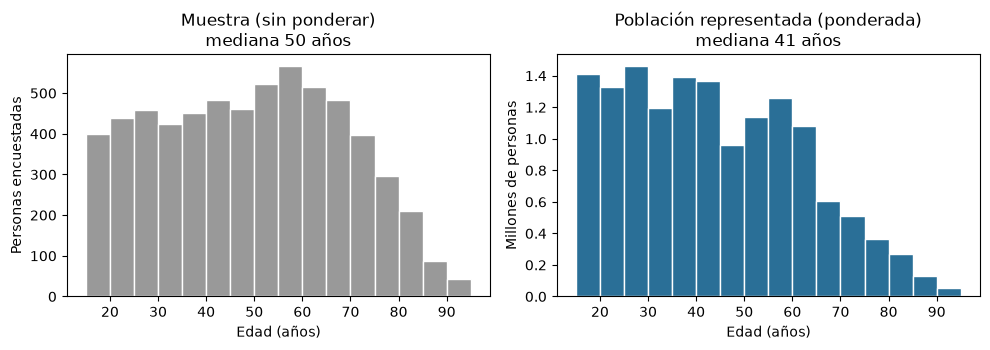

       % en la muestra  % en Chile (ponderado)
gedad                                         
15-24             13.4                    18.9
25-44             29.1                    37.3
45-64             33.1                    30.6
65+               24.3                    13.3
Fumador actual SIN ponderar: 28.2 %
Fumador actual PONDERADO:    {'%': 32.5, 'IC_inf': 30.4, 'IC_sup': 34.6, 'n': 6233}


In [7]:
bins = range(15, 100, 5)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(d.edad, bins=bins, color="#999999", edgecolor="white")
ax[0].set(title=f"Muestra (sin ponderar)\nmediana {d.edad.median():.0f} años", xlabel="Edad (años)", ylabel="Personas encuestadas")
ax[1].hist(d.edad, bins=bins, weights=d.w / 1e6, color="#2a6f97", edgecolor="white")
ax[1].set(title=f"Población representada (ponderada)\nmediana {cuantil_pond(d.edad):.0f} años", xlabel="Edad (años)", ylabel="Millones de personas")
plt.tight_layout(); plt.show()

comp = pd.DataFrame({"% en la muestra": d.gedad.value_counts(normalize=True, sort=False) * 100,
                     "% en Chile (ponderado)": d.groupby("gedad", observed=True).w.sum() / d.w.sum() * 100}).round(1)
print(comp)
print("Fumador actual SIN ponderar:", round(100 * d.fuma_actual.mean(), 1), "%")
print("Fumador actual PONDERADO:   ", prevalencia(d.fuma_actual).to_dict())

## 5. Parte B — Prevalencias

### ✏️ Ejercicio 2 — Prevalencia de fumadores

Calcula la prevalencia de **fumador actual** en toda la población y luego **por sexo, por zona (urbana/rural) y por grupo de edad**. ¿Quién fuma más?

> **Pista:** `prevalencia(d.fuma_actual)` da el total. Para un subgrupo pasa una máscara: `prevalencia(d.fuma_actual, d.sexo == 'Hombres')`.

In [8]:
print("Total:\n", prevalencia(d.fuma_actual).to_dict())
for g in ["sexo", "area", "gedad"]:
    for k in sorted(d[g].dropna().unique()):
        print(g, k, prevalencia(d.fuma_actual, d[g] == k).to_dict())

Total:
 {'%': 32.5, 'IC_inf': 30.4, 'IC_sup': 34.6, 'n': 6233}
sexo Hombres {'%': 36.7, 'IC_inf': 33.2, 'IC_sup': 40.1, 'n': 2315}
sexo Mujeres {'%': 28.5, 'IC_inf': 25.8, 'IC_sup': 31.2, 'n': 3918}
area Rural {'%': 21.9, 'IC_inf': 18.0, 'IC_sup': 25.7, 'n': 991}
area Urbana {'%': 33.8, 'IC_inf': 31.5, 'IC_sup': 36.2, 'n': 5242}
gedad 15-24 {'%': 30.0, 'IC_inf': 25.3, 'IC_sup': 34.8, 'n': 837}
gedad 25-44 {'%': 42.7, 'IC_inf': 38.5, 'IC_sup': 46.8, 'n': 1815}
gedad 45-64 {'%': 30.6, 'IC_inf': 26.6, 'IC_sup': 34.5, 'n': 2064}
gedad 65+ {'%': 11.9, 'IC_inf': 8.8, 'IC_sup': 15.0, 'n': 1517}


### ✏️ Ejercicio 3 — Fumador pasivo y su definición

Define **fumador pasivo** como una persona que **no fuma actualmente** (nunca o ex) y está **expuesta al humo ajeno** (`exp_any == 1`).

a) Calcula su prevalencia total y en los tres ambientes (casa, trabajo/estudio, otros).

b) Entre quienes no fuman, dibuja el histograma de horas diarias de exposición (`h_exp`). ¿Qué porcentaje no tiene ninguna exposición? Entre los expuestos, ¿cuál es la mediana de horas?

c) Recalcula la prevalencia de fumador pasivo exigiendo **≥ 2** y **≥ 5** horas diarias en vez de ≥ 1. ¿Cuánto depende el resultado de la regla que elegimos?

> **Pista:** Usa una máscara: `no_fuma = d.estado.isin(['nunca','ex'])`. Para los umbrales: `prevalencia((d.h_exp >= k).astype(float), no_fuma)` con `k = 1, 2, 5`.

Pasivo (no fuma + expuesto): {'%': 25.9, 'IC_inf': 23.1, 'IC_sup': 28.6, 'n': 4473}
exp_casa {'%': 7.3, 'IC_inf': 5.7, 'IC_sup': 8.8, 'n': 4473}
exp_trab {'%': 14.0, 'IC_inf': 11.8, 'IC_sup': 16.2, 'n': 4473}
exp_otro {'%': 14.7, 'IC_inf': 12.5, 'IC_sup': 16.8, 'n': 4473}


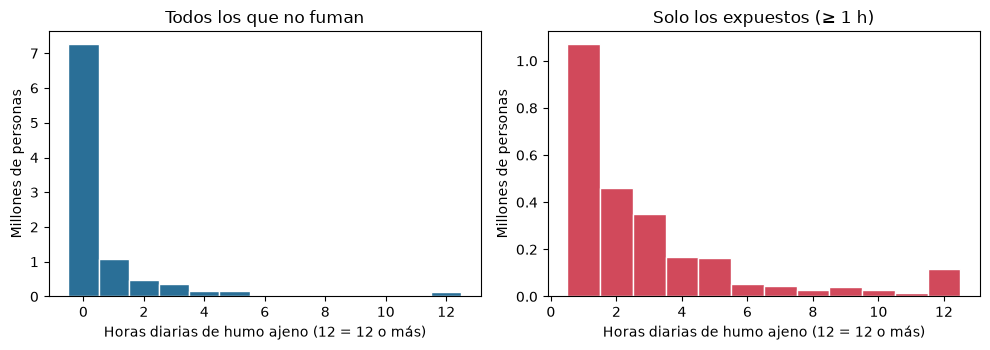

Sin ninguna exposición: 74.1%
Entre expuestos: {'n': 762, 'media': 3.3, 'p25': 1.0, 'mediana': 2.0, 'p75': 4.0}
Pasivo con ≥ 1 h/día: {'%': 25.9, 'IC_inf': 23.1, 'IC_sup': 28.6, 'n': 4473}
Pasivo con ≥ 2 h/día: {'%': 14.9, 'IC_inf': 12.9, 'IC_sup': 16.9, 'n': 4473}
Pasivo con ≥ 5 h/día: {'%': 4.9, 'IC_inf': 3.7, 'IC_sup': 6.2, 'n': 4473}


In [9]:
no_fuma = d.estado.isin(["nunca", "ex"])
print("Pasivo (no fuma + expuesto):", prevalencia(d.exp_any, no_fuma).to_dict())
for amb in ["exp_casa", "exp_trab", "exp_otro"]:
    print(amb, prevalencia(d[amb], no_fuma).to_dict())

expuesto = no_fuma & (d.h_exp > 0)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].hist(d.h_exp[no_fuma].clip(upper=12), bins=np.arange(-0.5, 12.6), weights=d.w[no_fuma] / 1e6, color="#2a6f97", edgecolor="white")
ax[0].set(title="Todos los que no fuman", xlabel="Horas diarias de humo ajeno (12 = 12 o más)", ylabel="Millones de personas")
ax[1].hist(d.h_exp[expuesto].clip(upper=12), bins=np.arange(0.5, 12.6), weights=d.w[expuesto] / 1e6, color="#d1495b", edgecolor="white")
ax[1].set(title="Solo los expuestos (≥ 1 h)", xlabel="Horas diarias de humo ajeno (12 = 12 o más)", ylabel="Millones de personas")
plt.tight_layout(); plt.show()
print(f"Sin ninguna exposición: {100 - prevalencia(d.exp_any, no_fuma)['%']:.1f}%")
print("Entre expuestos:", resumen(d.h_exp, expuesto).to_dict())
for k in [1, 2, 5]:
    print(f"Pasivo con ≥ {k} h/día:", prevalencia((d.h_exp >= k).astype(float), no_fuma).to_dict())

## 6. Parte C — Antes de comparar: ¿se parecen los grupos?

Si dos grupos difieren en **otras** características, comparar sus resultados sin cuidado lleva a conclusiones falsas. Aquí miramos la edad de fumadores y no fumadores y,
de forma opcional, qué variables se mueven juntas (**correlación**: un número entre −1 y +1 que mide cuánto *acompañan* dos variables entre sí; **no dice que una cause la otra**).

### ✏️ Ejercicio 4 — ¿Tienen la misma edad fumadores y no fumadores?

Dibuja, superpuestos, los histogramas de edad de fumadores actuales y de no fumadores (ponderados y normalizados para poder compararlos). Calcula la edad media de cada grupo. **Antes** de correr ningún modelo: si los fumadores son más jóvenes, ¿qué esperas que pase con su riesgo de morir *sin ajustar*?

> **Pista:** `plt.hist(s.edad, bins=range(15, 100, 5), weights=s.w, density=True, alpha=.55)` para cada grupo.

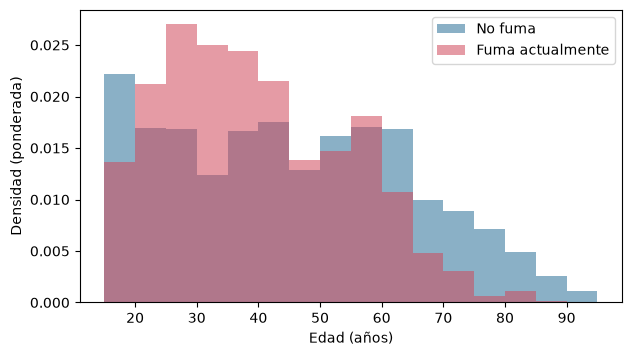

Edad media sin ponderar: {'No fuma': 51.2, 'Fuma actualmente': 43.1}
Edad media ponderada:    {'No fuma': 45.0, 'Fuma actualmente': 39.3}


In [10]:
z = d[d.fuma_actual.notna() & (d.w > 0)]
fig, ax = plt.subplots(figsize=(7, 3.8))
for v, lab, col in [(0, "No fuma", "#2a6f97"), (1, "Fuma actualmente", "#d1495b")]:
    s = z[z.fuma_actual == v]
    ax.hist(s.edad, bins=range(15, 100, 5), weights=s.w, density=True, alpha=.55, color=col, label=lab)
ax.set(xlabel="Edad (años)", ylabel="Densidad (ponderada)"); ax.legend(); plt.show()
nombre = {0.0: "No fuma", 1.0: "Fuma actualmente"}
print("Edad media sin ponderar:", {nombre[v]: round(float(s.edad.mean()), 1) for v, s in z.groupby("fuma_actual")})
print("Edad media ponderada:   ", {nombre[v]: round(float(np.average(s.edad, weights=s.w)), 1) for v, s in z.groupby("fuma_actual")})

### ✏️ Ejercicio 5 — (Opcional) ¿Qué variables se mueven juntas? (correlaciones)

Calcula la matriz de correlaciones (Spearman ponderada) entre `edad`, `cig_dia`, `h_casa`, `h_trab`, `h_otro`, `imc` y `colest`, y dibújala como mapa de calor. a) ¿Qué variable se correlaciona con más de las otras? b) ¿Qué ambientes de exposición van juntos? c) ¿Qué te dice esto sobre ajustar por edad? d) ¿Por qué una correlación de 0,28 *no* demuestra que la edad suba el colesterol por sí sola?

> **Pista:** `R = corr_pond(d, columnas)`; para el gráfico, `plt.imshow(R, cmap='RdBu_r', vmin=-1, vmax=1)`. Ojo con cuántos casos tiene cada par: `cig_dia` solo existe para fumadores actuales.

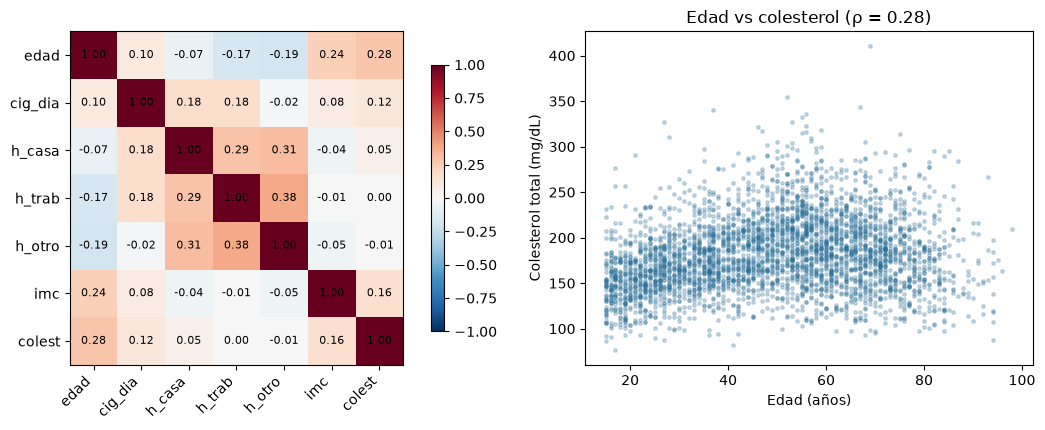

,edad,cig_dia,h_casa,h_trab,h_otro,imc,colest
edad,1.00,0.10,-0.07,-0.17,-0.19,0.24,0.28
cig_dia,0.10,1.00,0.18,0.18,-0.02,0.08,0.12
h_casa,-0.07,0.18,1.00,0.29,0.31,-0.04,0.05
h_trab,-0.17,0.18,0.29,1.00,0.38,-0.01,0.00
h_otro,-0.19,-0.02,0.31,0.38,1.00,-0.05,-0.01
imc,0.24,0.08,-0.04,-0.01,-0.05,1.00,0.16
colest,0.28,0.12,0.05,0.00,-0.01,0.16,1.00


In [11]:
cols = ["edad", "cig_dia", "h_casa", "h_trab", "h_otro", "imc", "colest"]
R = corr_pond(d, cols)
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.4), gridspec_kw={"width_ratios": [1.25, 1]})
im = ax[0].imshow(R, cmap="RdBu_r", vmin=-1, vmax=1)
ax[0].set_xticks(range(len(cols)), cols, rotation=45, ha="right"); ax[0].set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax[0].text(j, i, f"{R.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax[0], shrink=.8)
ax[1].scatter(d.edad, d.colest, s=6, alpha=.25, color="#2a6f97")
ax[1].set(xlabel="Edad (años)", ylabel="Colesterol total (mg/dL)", title=f"Edad vs colesterol (ρ = {R.loc['edad', 'colest']:.2f})")
plt.tight_layout(); plt.show()
R.round(2)

## 7. Parte D — ¿Fumar se asocia con morir antes?

### Cómo leer un HR (el modelo de Cox, en simple)

Queremos comparar qué tan probable es morir en distintos grupos. Hay un detalle: **no todos fueron seguidos el mismo tiempo**.
Una persona encuestada a inicios de 2016 tiene más años de seguimiento que una de 2017, y quienes siguen vivos en 2023 solo sabemos que sobrevivieron *al menos* hasta esa fecha.

El **modelo de Cox** resuelve esto: compara el riesgo de morir **en cada momento** del seguimiento entre los grupos, usando a quienes seguían vivos en ese momento. Así aprovecha a todos.
Su resultado es el **HR** (*hazard ratio*, razón de riesgos). No necesitas la matemática; basta saber leerlo:

| HR | Significa |
|---|---|
| 1 | el grupo tiene el mismo riesgo de morir que el grupo de comparación |
| 2 | el doble de riesgo |
| 0,5 | la mitad del riesgo |

Cada HR viene con su **intervalo de confianza (IC 95%)**: si el rango incluye al 1, la diferencia no es clara.
**Ajustar** por edad y sexo significa comparar personas de la misma edad y sexo, para que eso no distorsione el resultado.

### ✏️ Ejercicio 6 — El resultado engañoso

Retoma lo que viste en el ejercicio 4. Compara el **porcentaje de fallecidos** entre fumadores actuales y no fumadores (sin ajustar) y luego estima el HR **sin ajustar** con `cox(['fuma_actual'])`. ¿Fumar parece proteger? ¿Qué falta?

> **Pista:** Compara también la **edad media** de ambos grupos: `d.groupby('fuma_actual').edad.mean()`.

In [12]:
print(d.groupby("fuma_actual").muerto.mean().mul(100).round(1))
print(d.groupby("fuma_actual").edad.mean().round(1))
cox(["fuma_actual"])

fuma_actual
0.0    9.9
1.0    5.6
Name: muerto, dtype: float64
fuma_actual
0.0    51.2
1.0    43.1
Name: edad, dtype: float64


n = 6233 | muertes = 539


,HR,IC_inf,IC_sup,p
covariate,,,,
fuma_actual,0.664,0.441,1.0,0.05


### ✏️ Ejercicio 7 — Ajustar por edad y sexo

Repite el modelo agregando `edad` y `mujer`. ¿Qué pasa con el HR de `fuma_actual`? Explica **por qué** cambia.

> **Pista:** `cox(['fuma_actual','edad','mujer'])`.

In [13]:
cox(["fuma_actual", "edad", "mujer"])

n = 6233 | muertes = 539


,HR,IC_inf,IC_sup,p
covariate,,,,
fuma_actual,1.827,1.305,2.558,0.000
edad,1.105,1.093,1.118,0.000
mujer,0.782,0.594,1.028,0.078


### ✏️ Ejercicio 8 — Fumadores activos, ex fumadores y pasivos

Arma cuatro grupos: **(ref.) nunca fumó y sin exposición**, **pasivo** (nunca fumó y expuesto), **ex fumador** y **fumador actual**. Estima el HR de cada uno ajustando por edad y sexo. ¿Hay evidencia de riesgo en los pasivos? Mira el **número de muertes** de ese grupo antes de concluir.

> **Pista:** Crea tres columnas 0/1 (`pasivo`, `ex`, `actual`) y pásalas a `cox(...)` junto a `edad` y `mujer`. Usa solo las filas con `estado` no nulo.

In [14]:
g = d[d.estado.notna()].copy()
g["pasivo"] = ((g.estado == "nunca") & (g.exp_any == 1)).astype(float)
g["ex"]     = (g.estado == "ex").astype(float)
g["actual"] = g.estado.isin(["diario", "ocasional"]).astype(float)
print(g.assign(grupo=np.select([g.actual == 1, g.ex == 1, g.pasivo == 1], ["actual", "ex", "pasivo"], "ref (nunca, sin exp.)"))
        .groupby("grupo").muerto.agg(["count", "sum"]))
cox(["pasivo", "ex", "actual", "edad", "mujer"], g)

                       count  sum
grupo                            
actual                  1760   98
ex                      1456  172
pasivo                   473   24
ref (nunca, sin exp.)   2544  245


n = 6233 | muertes = 539


,HR,IC_inf,IC_sup,p
covariate,,,,
pasivo,0.632,0.345,1.158,0.138
ex,1.327,0.990,1.779,0.059
actual,2.035,1.430,2.895,0.000
edad,1.105,1.093,1.118,0.000
mujer,0.820,0.620,1.084,0.163


## 8. Parte E — Curvas de supervivencia

Las curvas muestran la proporción de personas vivas a lo largo del tiempo. Comparar **dentro de un grupo de edad** evita la confusión que viste en el ejercicio 6.

### ✏️ Ejercicio 9 — Curva por grupo de edad

Dibuja la supervivencia de fumadores y no fumadores solo entre personas de **40 a 59 años**. ¿Se separan las curvas?

> **Pista:** Usa `KaplanMeierFitter().fit(tiempo, evento, weights=peso)` y `.plot_survival_function()`.

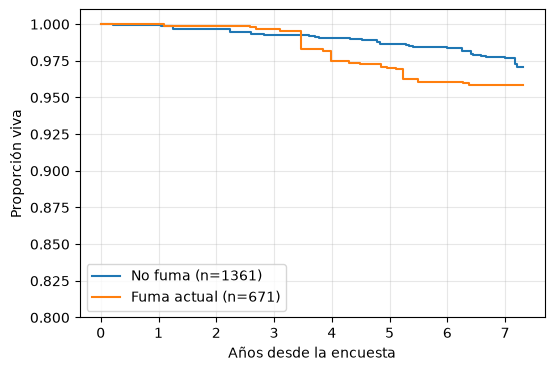

In [15]:
z = d[(d.edad.between(40, 59)) & d.fuma_actual.notna() & (d.w > 0)]
fig, ax = plt.subplots(figsize=(6, 4))
for v, lab in [(0, "No fuma"), (1, "Fuma actual")]:
    s = z[z.fuma_actual == v]
    KaplanMeierFitter().fit(s.t, s.muerto, weights=s.w, label=f"{lab} (n={len(s)})").plot_survival_function(ax=ax, ci_show=False)
ax.set_ylim(0.8, 1.01); ax.set_xlabel("Años desde la encuesta"); ax.set_ylabel("Proporción viva"); ax.grid(alpha=.3)
plt.show()

## 9. Preguntas para discutir en grupo
1. ¿Por qué el HR sin ajustar (< 1) y el ajustado (> 1) apuntan en direcciones opuestas? ¿Qué otras variables podrían confundir?
2. ¿Qué cambiaría si definimos fumador pasivo con otro umbral? ¿Cómo lo probarías?
3. ¿Qué otras preguntas podrías responder con esta base? (por ejemplo: hipertensión, diabetes, obesidad, o la misma pregunta en la ENS 2003 y 2009-10).
4. La edad se correlaciona con el colesterol, el IMC y la exposición al humo. ¿Qué otras variables deberías medir y ajustar antes de interpretar un HR como efecto del tabaco?

---
**Fuentes:** Ministerio de Salud de Chile, Departamento de Epidemiología. *Encuesta Nacional de Salud 2016-2017*, base de datos y manual de uso. https://epi.minsal.cl/bases-de-datos/